# 02.4 · Model comparison: which model best predicts a popular Kindle book?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Answer: yes, partly.**

- I chose **gradient boosting** by its validation score. On **27,169 test books** from new authors it reaches **ROC AUC 0.809** and accuracy **75.7%**, against 0.500 and 67.6%
  for the baseline.
- It finds **51.1%** of the popular books, and **66.2%** of the books it calls popular really are.
- It relies most on the **author's earlier books**, then on **length**.
- Its main weakness: at a threshold of 0.5 it finds only **3.8%** of popular first books.

## 2. Recap

**Question.** Can we predict, from the characteristics of a book draft, whether a new Kindle book will reach at least 100 ratings in its
first 12 months on Amazon?

Notebooks 02.1, 02.2 and 02.3 trained logistic regression, a random forest and gradient boosting on the same training books, and tested
them on the same **27,169 test books** from authors they had not seen. This notebook compares them and chooses the final model.

## 3. Setup

I load the saved predictions and results of the three notebooks. No model is trained here.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
TARGET = "popular_first_year"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

MODELS = {"Logistic regression": "logistic", "Random forest": "random_forest", "Gradient boosting": "gradient_boosting"}
predictions = {name: pd.read_parquet(PROCESSED / f"predictions_popularity_{slug}.parquet").set_index("parent_asin")
               for name, slug in MODELS.items()}
summaries = {name: json.loads((PROCESSED / f"results_popularity_{slug}.json").read_text(encoding="utf-8")) for name, slug in MODELS.items()}
first = predictions["Logistic regression"]
print("Test books:", len(first))
print("Same test books in all notebooks:", all(set(p.index) == set(first.index) for p in predictions.values()))

Test books: 27169
Same test books in all notebooks: True


- All three notebooks use exactly the same **27,169 test books** (`True`), so the comparison is fair.

## 4. Feature preparation

All models use the same six characteristics: niche, pages, title words, series, self-published and the author's earlier books. Logistic
regression uses the logarithm of earlier books; the tree models use the original number.

## 5. Train/test split

All notebooks use the same split: 108,670 training books and 27,169 test books, with no author on both sides.

## 6. Baseline

The baseline always says "not popular". I calculate it on the same test books.

In [2]:
y_test = first[TARGET]


def measures(true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {"accuracy": accuracy_score(true, predicted), "precision": precision_score(true, predicted, zero_division=0),
            "recall": recall_score(true, predicted, zero_division=0), "f1": f1_score(true, predicted, zero_division=0),
            "roc_auc": roc_auc_score(true, probability)}


pd.DataFrame({"baseline": measures(y_test, np.zeros(len(y_test)))}).T.round(3)

,accuracy,precision,recall,f1,roc_auc
baseline,0.676,0.0,0.0,0.0,0.5


- The baseline is right for **67.6%** of the books but finds no popular book, and its ROC AUC is **0.5**.

## 7. Candidate models

The choice must **not** use the test books, so I first compare the **validation ROC AUC** from the grid searches. `gap` is the difference between
training and validation: a larger gap means more overfitting.

In [3]:
validation = pd.DataFrame({name: {"validation_roc_auc": s["cv_roc_auc"], "std_between_folds": s["cv_std"], "train_roc_auc": s["train_roc_auc"],
                                  "best_settings": str(s["best_params"])} for name, s in summaries.items()}).T
validation[["validation_roc_auc", "std_between_folds", "train_roc_auc"]] = validation[["validation_roc_auc", "std_between_folds", "train_roc_auc"]].astype(float)
validation["gap"] = validation["train_roc_auc"] - validation["validation_roc_auc"]
validation = validation.sort_values("validation_roc_auc", ascending=False)
FINAL = validation.index[0]
print("Chosen by validation ROC AUC:", FINAL)
validation.round(4)

Chosen by validation ROC AUC: Gradient boosting


,validation_roc_auc,std_between_folds,train_roc_auc,best_settings,gap
Gradient boosting,0.8018,0.0032,0.8143,"{'learning_rate': 0.05, 'max_iter': 150, 'max_...",0.0125
Random forest,0.7993,0.0036,0.8299,"{'max_depth': None, 'min_samples_leaf': 20}",0.0306
Logistic regression,0.7739,0.0030,0.7746,{'C': 0.1},0.0007


- **Gradient boosting** has the highest validation ROC AUC (**0.8018**), just above the **random forest** (0.7993) and clearly above **logistic regression** (0.7739). It is chosen as the final model.
- Its gap between training and validation is small (**0.0125**), against 0.0306 for the forest.
- Logistic regression has almost no gap (0.0007) and is the easiest to explain, but it ranks books less well.

## 8. Evaluation

Now I show all models on the test books, with the threshold of 0.5.

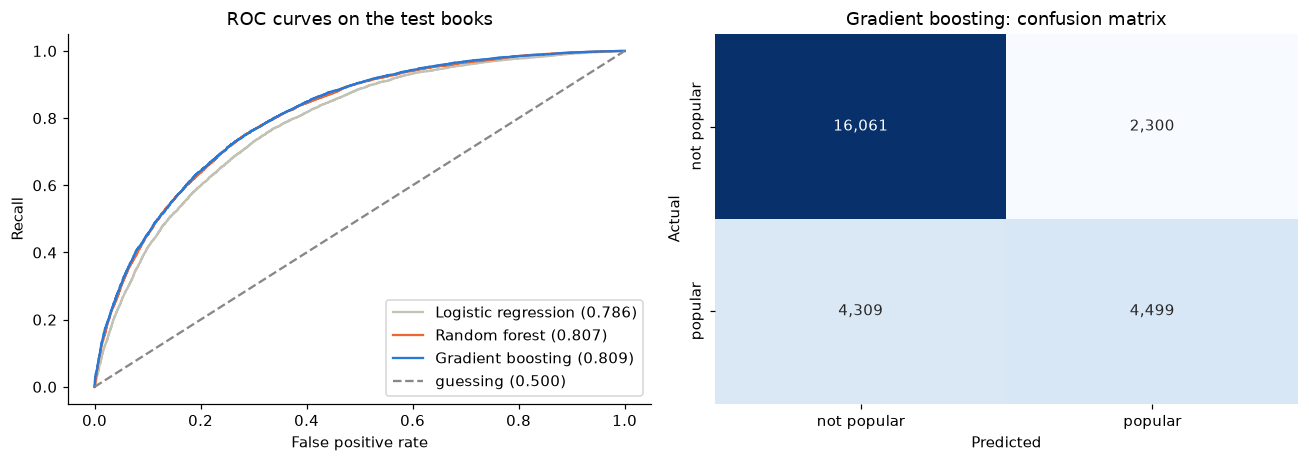

,accuracy,precision,recall,f1,roc_auc
baseline,0.676,0.000,0.000,0.000,0.500
Logistic regression,0.743,0.654,0.439,0.525,0.786
Random forest,0.757,0.669,0.493,0.568,0.807
Gradient boosting,0.757,0.662,0.511,0.577,0.809


In [4]:
test_scores = pd.DataFrame({"baseline": measures(y_test, np.zeros(len(y_test))),
                            **{name: measures(p[TARGET], p["probability"]) for name, p in predictions.items()}}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for (name, p), color in zip(predictions.items(), [GREY, ORANGE, BLUE]):
    fpr, tpr, _ = roc_curve(p[TARGET], p["probability"])
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(p[TARGET], p['probability']):.3f})")
axes[0].plot([0, 1], [0, 1], color="#888888", linestyle="--", label="guessing (0.500)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("Recall")
axes[0].set_title("ROC curves on the test books")
axes[0].legend()
final = predictions[FINAL]
sns.heatmap(confusion_matrix(final[TARGET], final["predicted"]), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["not popular", "popular"], yticklabels=["not popular", "popular"])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"{FINAL}: confusion matrix")
plt.tight_layout()
plt.show()
test_scores.round(3)

- The test results agree with the choice: ROC AUC **0.809** for gradient boosting, **0.807** for the random forest and **0.786** for logistic regression.
- Gradient boosting and the forest are almost equal in accuracy (**0.757**). Boosting has the higher recall (0.511 against 0.493) and the forest the slightly higher precision (0.669 against 0.662).
- The final model finds **4,499** popular books, misses **4,309** and raises **2,300** false alarms.

The final model gives probabilities, so a user can choose a threshold. This table shows the choices for the final model.

In [5]:
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    row = measures(final[TARGET], final["probability"], threshold)
    row.update({"threshold": threshold, "books_called_popular": int((final["probability"] >= threshold).sum())})
    rows.append(row)
pd.DataFrame(rows).set_index("threshold").drop(columns="roc_auc").round(3)

,accuracy,precision,recall,f1,books_called_popular
threshold,,,,,
0.2,0.644,0.474,0.892,0.619,16573
0.3,0.711,0.537,0.790,0.639,12951
0.4,0.746,0.599,0.659,0.627,9697
0.5,0.757,0.662,0.511,0.577,6799
0.6,0.748,0.728,0.357,0.479,4320
0.7,0.723,0.790,0.197,0.316,2200


- The default 0.5 finds **51.1%** of popular books with a precision of **66.2%**.
- For an author who does not want to miss a promising book, **0.3** is more useful: it finds **79.0%**, with a precision of **53.7%**.
- At **0.7** the model is right **79.0%** of the time, but it finds only 19.7%. F1 is highest at 0.3 (0.639).

## 9. Error analysis

I compare the models for the groups that matter most for new authors: self-published books and authors with few earlier books.

In [6]:
def group_table(labels):
    rows = []
    for name, p in predictions.items():
        for group, part in p.groupby(labels.loc[p.index], observed=True):
            rows.append({"group": group, "model": name, "books": len(part), "actual_%": part[TARGET].mean() * 100,
                         "recall": recall_score(part[TARGET], part["predicted"], zero_division=0),
                         "precision": precision_score(part[TARGET], part["predicted"], zero_division=0),
                         "roc_auc": roc_auc_score(part[TARGET], part["probability"])})
    return pd.DataFrame(rows).set_index(["group", "model"])


route = pd.Series(np.where(first["self_published"] == 1, "self-published", "publisher"), index=first.index)
experience = pd.cut(first["author_earlier_books"], [-1, 0, 2, 9, np.inf], labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])
display(group_table(route).round(3))
group_table(experience).round(3)

,,books,actual_%,recall,precision,roc_auc
group,model,,,,,
publisher,Logistic regression,9991,46.912,0.568,0.654,0.706
self-published,Logistic regression,17178,23.990,0.292,0.654,0.799
publisher,Random forest,9991,46.912,0.544,0.693,0.742
self-published,Random forest,17178,23.990,0.435,0.639,0.812
publisher,Gradient boosting,9991,46.912,0.565,0.690,0.743
self-published,Gradient boosting,17178,23.990,0.450,0.625,0.816


,,books,actual_%,recall,precision,roc_auc
group,model,,,,,
first book,Logistic regression,8411,13.042,0.001,0.143,0.734
1-2 earlier,Logistic regression,4712,20.947,0.019,0.594,0.712
3-9 earlier,Logistic regression,5729,32.798,0.180,0.527,0.665
10+ earlier,Logistic regression,8317,58.254,0.724,0.671,0.656
first book,Random forest,8411,13.042,0.042,0.575,0.764
1-2 earlier,Random forest,4712,20.947,0.081,0.576,0.741
3-9 earlier,Random forest,5729,32.798,0.195,0.581,0.697
10+ earlier,Random forest,8317,58.254,0.794,0.683,0.702
first book,Gradient boosting,8411,13.042,0.038,0.609,0.771


- **Self-published books:** gradient boosting finds **45.0%** of the popular ones, against 29.2% for logistic regression.
- **First books:** all models find very few (recall **0.038** for boosting and 0.042 for the forest). Boosting still ranks them fairly well (ROC AUC **0.771**).
- **Authors with 10+ earlier books:** recall is **0.804**. The models work much better for experienced authors.

## 10. Interpretation

Permutation importance from each notebook shows how much the ROC AUC falls when one feature is shuffled.

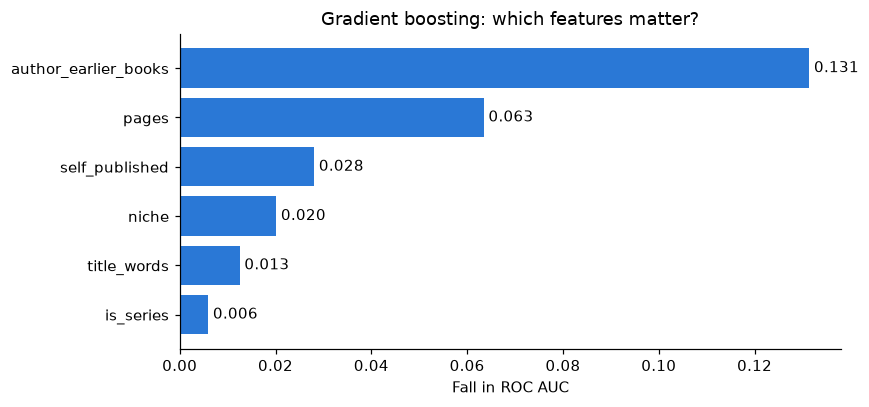

,Logistic regression,Random forest,Gradient boosting
author_earlier_books,0.135,0.132,0.131
pages,0.020,0.049,0.063
self_published,0.026,0.032,0.028
niche,0.018,0.021,0.020
title_words,0.003,0.010,0.013
is_series,0.011,0.009,0.006


In [7]:
importance = pd.DataFrame({name: s["importance"] for name, s in summaries.items()})
importance = importance.rename(index={"log_earlier_books": "author_earlier_books"}).groupby(level=0).sum()
importance = importance.sort_values(FINAL)
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(importance.index, importance[FINAL], color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Fall in ROC AUC")
ax.set_title(f"{FINAL}: which features matter?")
plt.tight_layout()
plt.show()
importance.sort_values(FINAL, ascending=False).round(3)

- In all three models the **author's earlier books** matter most (a fall of about **0.13**).
- In gradient boosting, **pages** are second (**0.063**), then **self-published** (0.028), **niche** (0.020), **title words** (0.013) and **series** (0.006).

## 11. Limitations & ethics

**Limitations**

- **The target is estimated.** First-year ratings come from dated reviews scaled to Amazon's total ratings, so books close to 100 can fall on the wrong side.
- **Ratings are not sales.** The model predicts reader response, not copies sold or income.
- **Only books with at least one review in the file are included**, so real chances for a new book are probably lower.
- `self_published` comes from my rule, and `author_earlier_books` counts only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data.
- The model was built on books from 2019–2021, so it may not hold for later years.
- The results show **associations, not causes**.

**Ethics**

- The model favours experienced authors. It should not decide which authors or books deserve support.
- It is meant as **information for an author**. A low chance does not mean that a book is bad.

## 12. Conclusion

**Answer to the question.** Yes, but only to a moderate degree. Gradient boosting predicts much better than the baseline (ROC AUC **0.809** against 0.500), and its probabilities are reliable enough to read as approximate chances.

**What it means.** Popular books more often come from experienced authors, are longer (up to about 400 pages), and are in strong niches such as Romance. Notebook 02.3 shows that with only the draft features the ROC AUC is **0.720**, so the
draft helps, but the author's history adds a lot.

**What it cannot do.** It rarely identifies a popular first book at the threshold of 0.5, and it does not predict sales or income.

**Possible next steps.** Add price as a separate test, and study reviews after publication with sentiment analysis.